# 01 - Exploratory Data Analysis
Heart Disease UCI (Cleveland) dataset: 303 patients, 13 features, binary target.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../src'))
os.chdir('..')  # run from the project root

In [2]:
import pandas as pd
from IPython.display import Image, display
from heart.data import load_clean
from heart import config

df = load_clean()
print(df.shape)
df.head()

(303, 14)


,age,trestbps,chol,thalach,oldpeak,ca,sex,cp,fbs,restecg,exang,slope,thal,target
0,63.0,145.0,233.0,150.0,2.3,0.0,1.0,1.0,1.0,2.0,0.0,3.0,6.0,0
1,67.0,160.0,286.0,108.0,1.5,3.0,1.0,4.0,0.0,2.0,1.0,2.0,3.0,1
2,67.0,120.0,229.0,129.0,2.6,2.0,1.0,4.0,0.0,2.0,1.0,2.0,7.0,1
3,37.0,130.0,250.0,187.0,3.5,0.0,1.0,3.0,0.0,0.0,0.0,3.0,3.0,0
4,41.0,130.0,204.0,172.0,1.4,0.0,0.0,2.0,0.0,2.0,0.0,1.0,3.0,0


# Data quality
Check types, missing values and value ranges.

In [3]:
df.info()
print('\nMissing values:')
print(df.isna().sum()[df.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   trestbps  303 non-null    float64
 2   chol      303 non-null    float64
 3   thalach   303 non-null    float64
 4   oldpeak   303 non-null    float64
 5   ca        299 non-null    float64
 6   sex       303 non-null    float64
 7   cp        303 non-null    float64
 8   fbs       303 non-null    float64
 9   restecg   303 non-null    float64
 10  exang     303 non-null    float64
 11  slope     303 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values:
ca      4
thal    2
dtype: int64


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0


# Class balance
The two classes are close to 54/46, so no resampling is needed; we still use stratified splits.

In [5]:
df[config.TARGET].value_counts(normalize=True).round(3)

target
0    0.541
1    0.459
Name: proportion, dtype: float64

# Charts
All charts are produced by `heart.eda` so the notebook and the CI pipeline create identical figures.

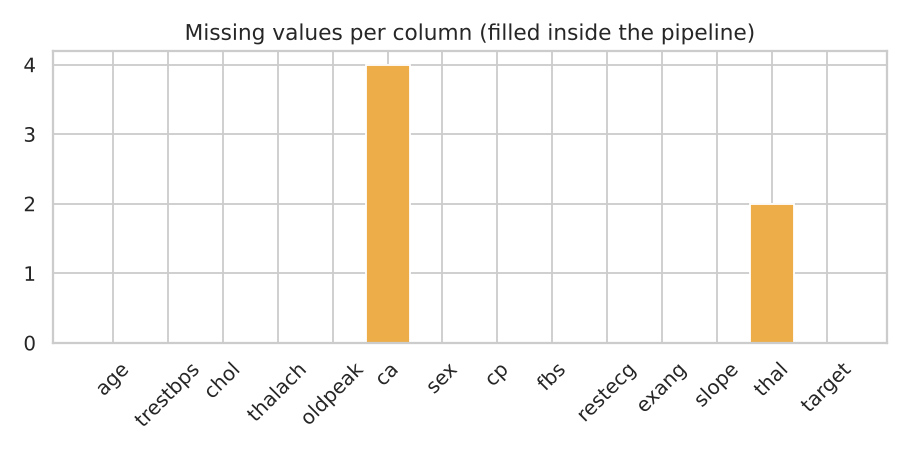

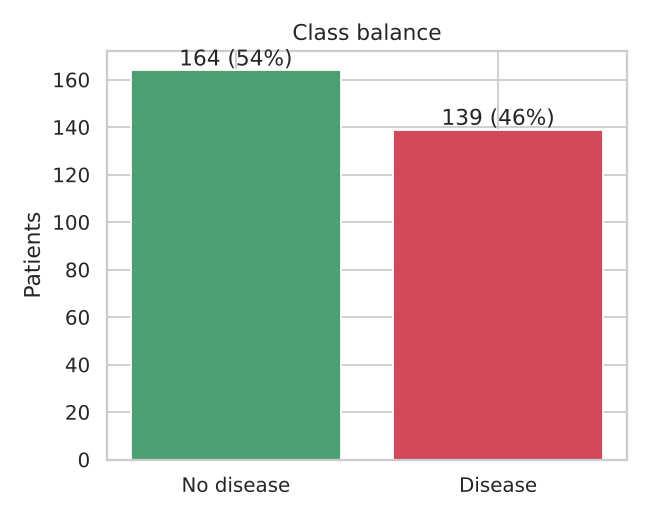

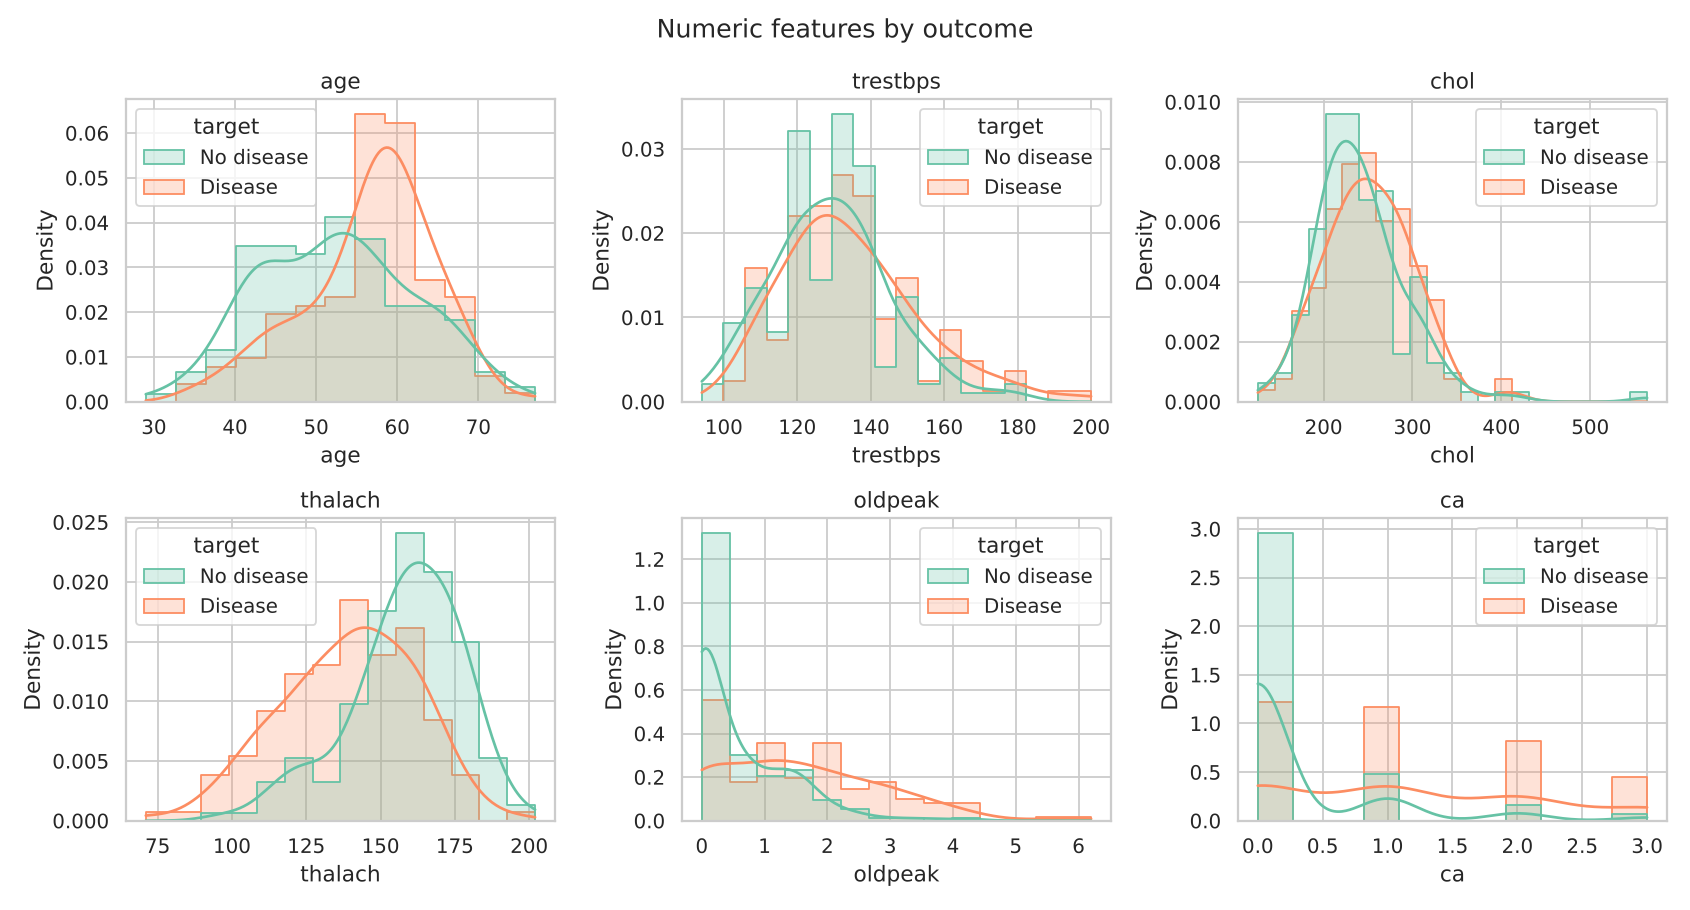

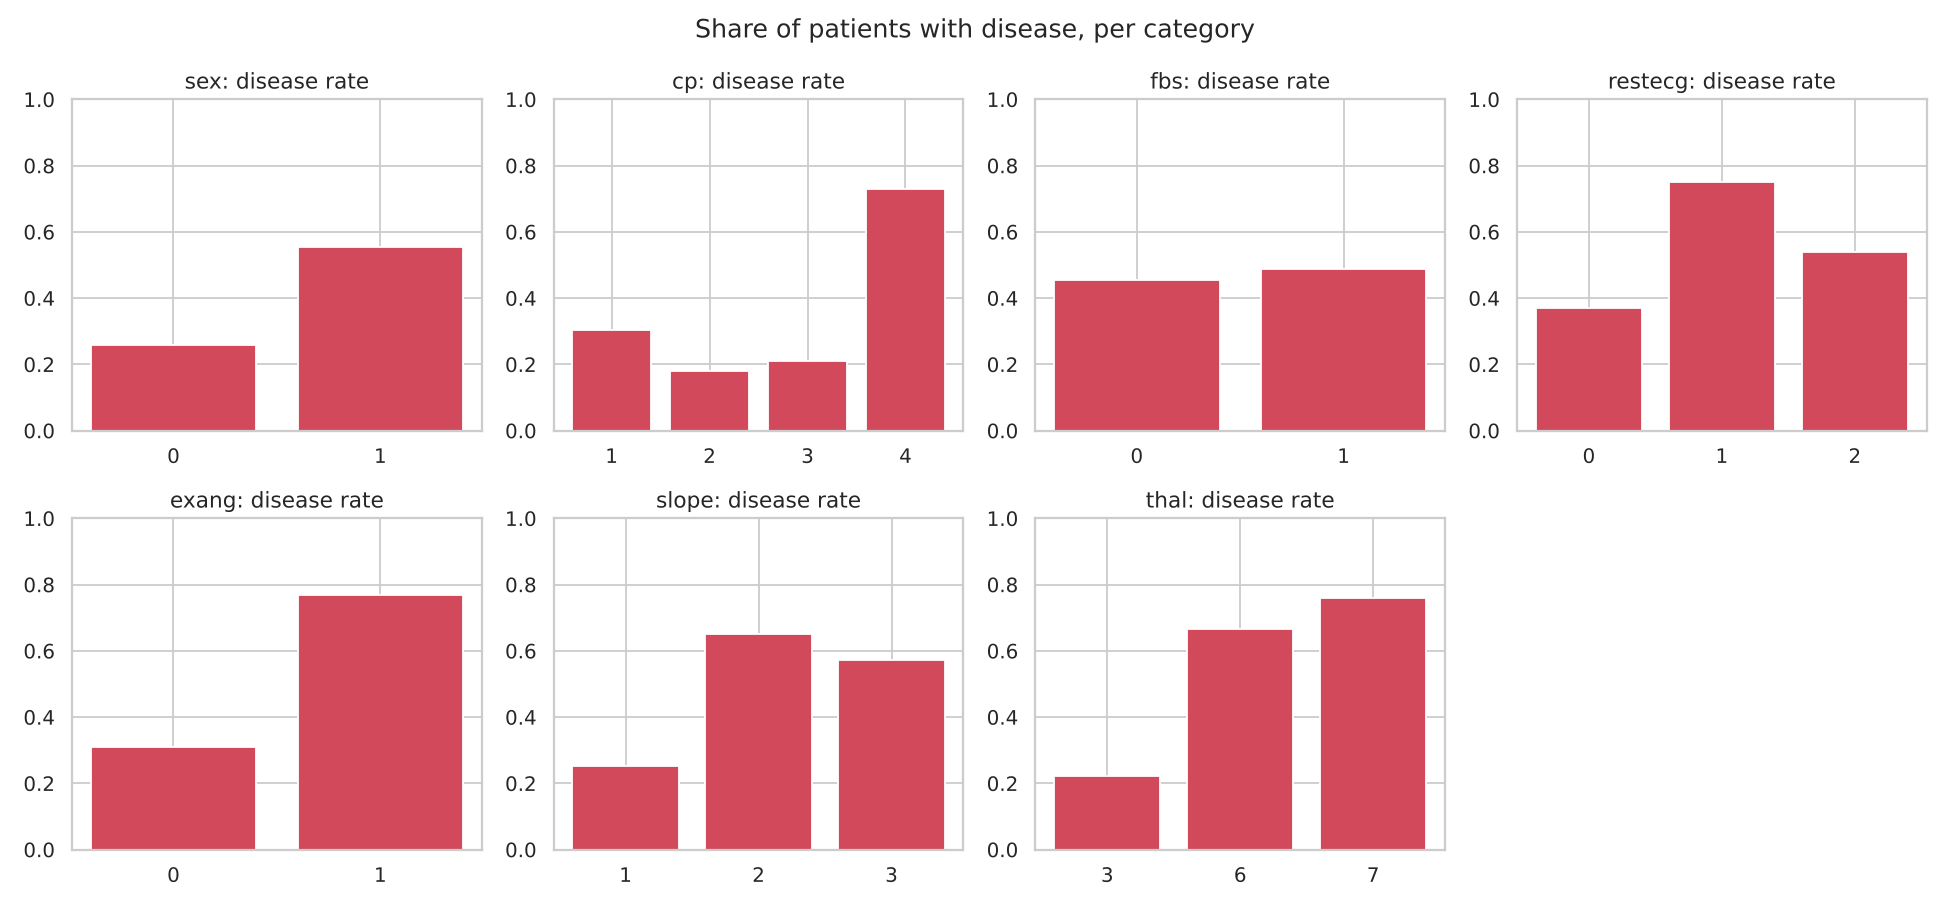

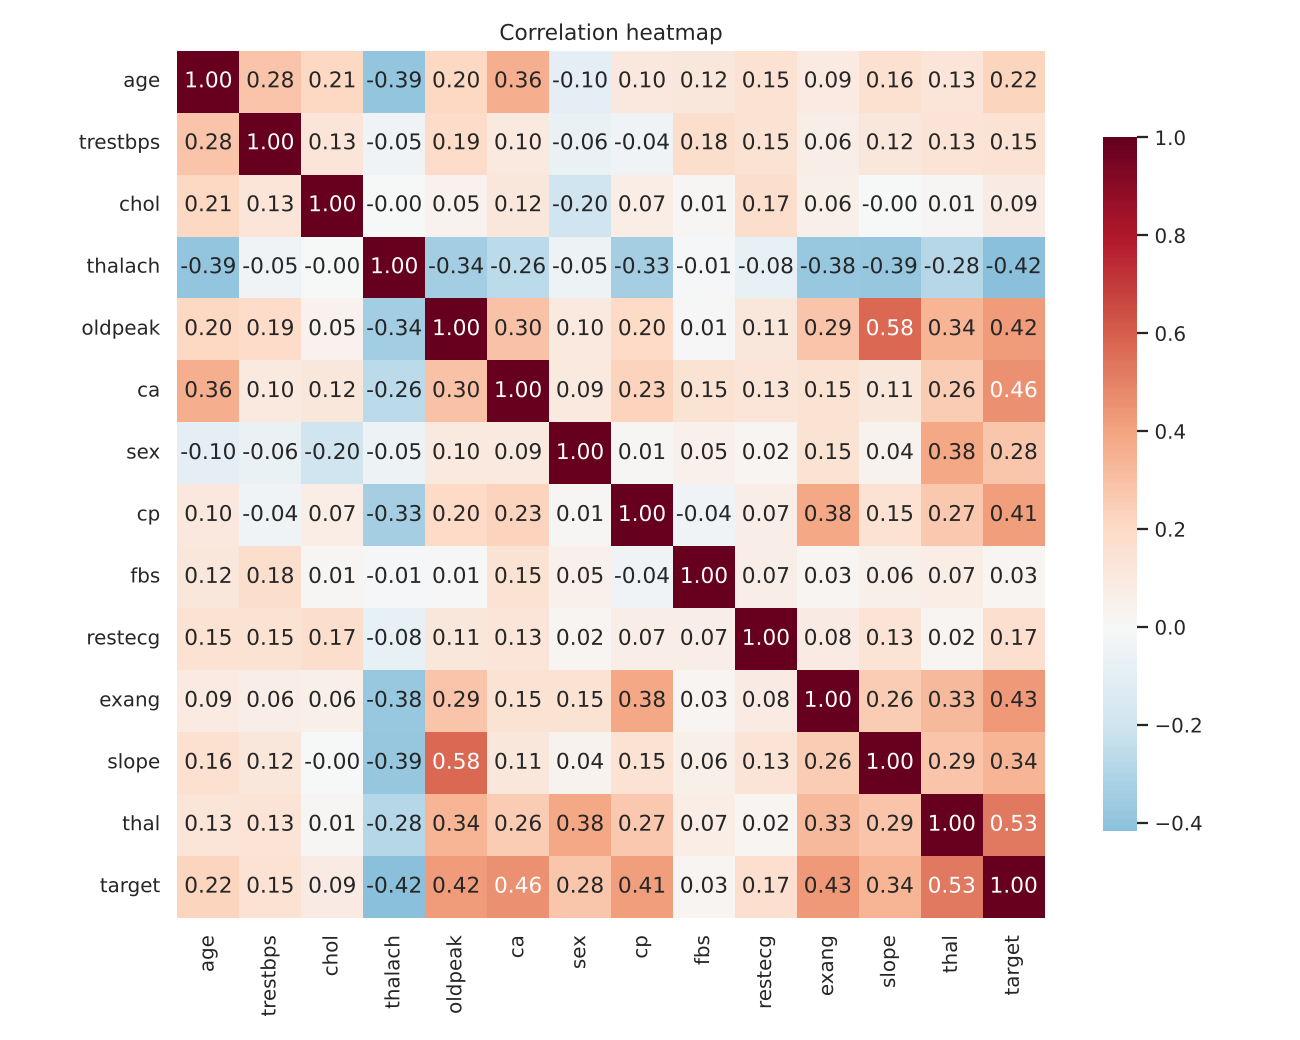

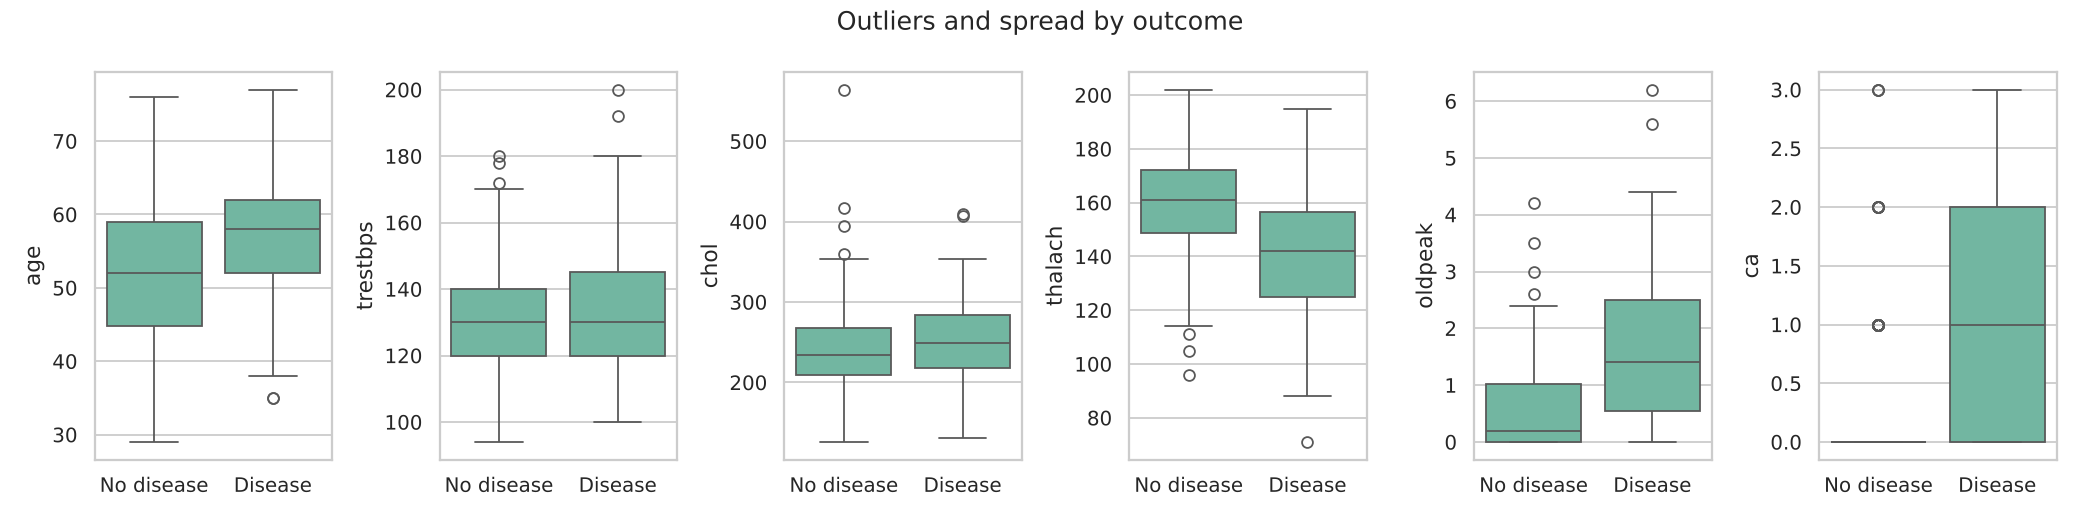

In [6]:
from heart.eda import run_all
for p in run_all():
    display(Image(filename=p))

# Strongest relationships with the target

In [7]:
df.corr(numeric_only=True)[config.TARGET].drop(config.TARGET).sort_values(key=abs, ascending=False).round(3)

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64

# Key findings
- `ca`, `thal`, `cp`, `oldpeak`, `exang` and `thalach` separate the classes most clearly.
- Only `ca` (4) and `thal` (2) have missing values; they are filled inside the model pipeline (median / most frequent) so serving uses the same logic.
- `cp`, `thal`, `restecg`, `slope` are codes, not quantities, so they are one-hot encoded instead of scaled.
- `chol` and `trestbps` have a few high outliers; tree models are robust to them and scaling limits their effect on logistic regression.